In [9]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [11]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\janas

Files in this folder:
['.anaconda', '.antigravity-ide', '.conda', '.continuum', '.copilot', '.eclipse', '.gemini', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.m2', '.neo-browser', '.p2', '.python_history', '.vscode', '.vscode-shared', 'anaconda3', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'Favorites', 'gold_price_diwali_2016_2026.csv', 'Links', 'Local Settings', 'MLT Project 1.ipynb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{d160d2b1-d4b7-11f0-b65d-806e6f6e6963}.TM.blf', 'NTUSER.DAT{d160d2b1-d4b7-11f0-b65d-806e6f6e6963}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{d160d2b1-d4b7-11f0-b65d-806e6f6e6963}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'student_academic_performance.csv', 'Templates', 'Untitl

In [12]:
df = pd.read_csv("student_academic_performance.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 15


In [14]:
df.head()

,Student_ID,Gender,Age,Study_Hours,Attendance_Percentage,Previous_Score,Assignment_Score,Internal_Marks,Sleep_Hours,Internet_Hours,Extracurricular_Level,Parent_Education,Study_Method,Final_Score,Performance
0,STU0001,Male,22,4.5,74.9,36.7,91.5,48.0,4.9,2.4,Medium,Graduate,Group Study,61.6,Average
1,STU0002,Female,17,5.1,97.2,93.9,81.9,55.4,8.1,1.5,High,Graduate,Self Study,82.1,Excellent
2,STU0003,Male,17,7.2,84.7,63.7,78.0,78.7,6.8,3.7,Low,Postgraduate,Group Study,81.2,Excellent
3,STU0004,Male,17,3.2,74.5,72.3,77.3,77.8,8.1,0.9,High,Diploma,Self Study,75.2,Good
4,STU0005,Male,21,5.5,86.4,67.3,64.2,64.9,6.7,5.7,High,Postgraduate,Group Study,69.2,Good


In [15]:
print(df.columns.tolist())

['Student_ID', 'Gender', 'Age', 'Study_Hours', 'Attendance_Percentage', 'Previous_Score', 'Assignment_Score', 'Internal_Marks', 'Sleep_Hours', 'Internet_Hours', 'Extracurricular_Level', 'Parent_Education', 'Study_Method', 'Final_Score', 'Performance']


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             1000 non-null   str    
 1   Gender                 1000 non-null   str    
 2   Age                    1000 non-null   int64  
 3   Study_Hours            1000 non-null   float64
 4   Attendance_Percentage  1000 non-null   float64
 5   Previous_Score         1000 non-null   float64
 6   Assignment_Score       1000 non-null   float64
 7   Internal_Marks         1000 non-null   float64
 8   Sleep_Hours            1000 non-null   float64
 9   Internet_Hours         1000 non-null   float64
 10  Extracurricular_Level  1000 non-null   str    
 11  Parent_Education       1000 non-null   str    
 12  Study_Method           1000 non-null   str    
 13  Final_Score            1000 non-null   float64
 14  Performance            1000 non-null   str    
dtypes: float64(8), i

In [17]:
print(df.isnull().sum())

Student_ID               0
Gender                   0
Age                      0
Study_Hours              0
Attendance_Percentage    0
Previous_Score           0
Assignment_Score         0
Internal_Marks           0
Sleep_Hours              0
Internet_Hours           0
Extracurricular_Level    0
Parent_Education         0
Study_Method             0
Final_Score              0
Performance              0
dtype: int64


In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [19]:
df = df.drop_duplicates()

print("Duplicates removed.")
print("New dataset size:", df.shape)

Duplicates removed.
New dataset size: (1000, 15)


In [20]:
df.describe()

,Age,Study_Hours,Attendance_Percentage,Previous_Score,Assignment_Score,Internal_Marks,Sleep_Hours,Internet_Hours,Final_Score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,19.473000,4.947800,77.964900,67.600600,71.227900,69.329400,6.775900,3.855700,68.794100
std,1.740776,1.926382,11.404525,15.047017,13.758523,12.820732,1.221516,1.980411,8.500912
min,17.000000,1.000000,45.000000,30.000000,27.500000,33.200000,4.000000,0.500000,39.800000
25%,18.000000,3.600000,70.300000,57.000000,62.475000,61.100000,5.900000,2.400000,63.200000
50%,19.000000,4.900000,78.000000,67.750000,71.850000,69.250000,6.800000,3.800000,68.800000
75%,21.000000,6.200000,85.800000,78.050000,80.900000,77.900000,7.600000,5.200000,74.600000
max,22.000000,10.000000,100.000000,100.000000,100.000000,100.000000,10.000000,10.000000,96.200000


In [21]:
print(df["Performance"].value_counts())

Performance
Good         576
Average      313
Excellent     96
Poor          15
Name: count, dtype: int64


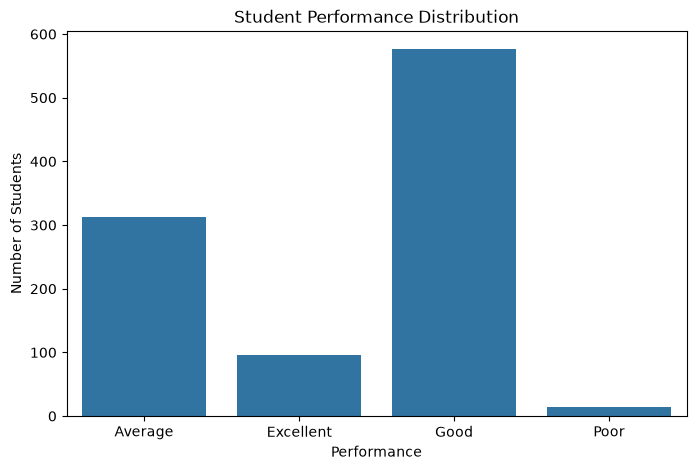

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Performance")

plt.title("Student Performance Distribution")
plt.xlabel("Performance")
plt.ylabel("Number of Students")

plt.show()

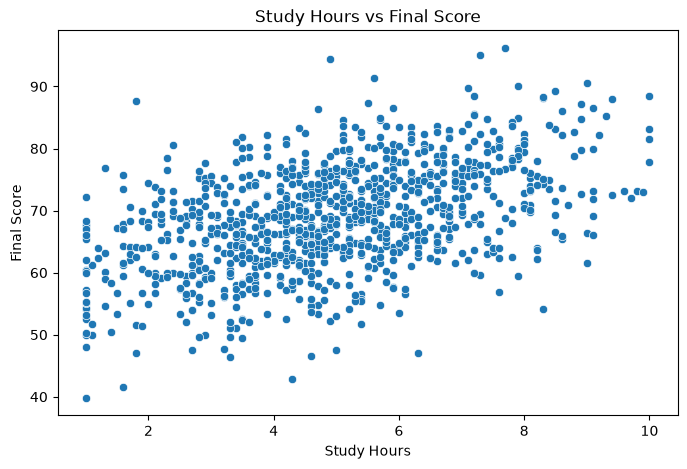

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Score"
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.show()

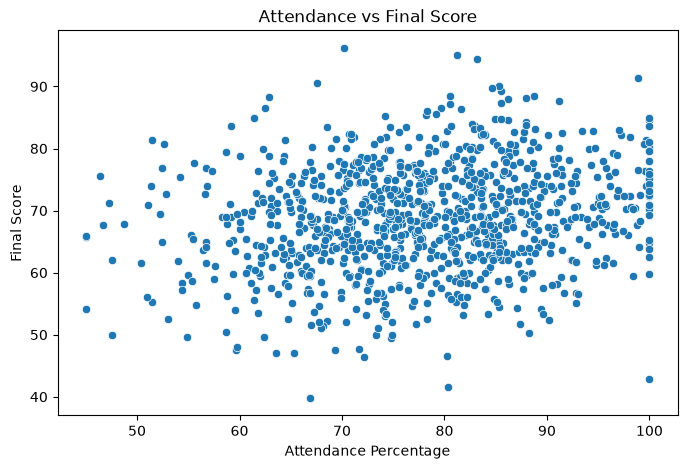

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance_Percentage",
    y="Final_Score"
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")

plt.show()

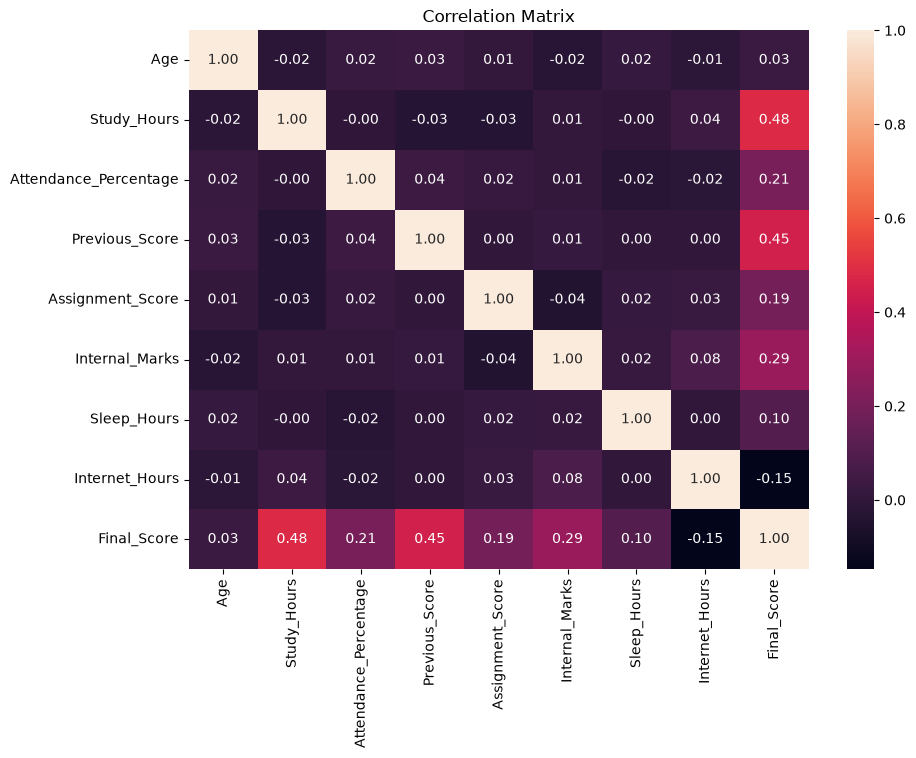

In [25]:
numeric_data = df.select_dtypes(include="number")

correlation = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [26]:
features = [
    "Age",
    "Study_Hours",
    "Attendance_Percentage",
    "Previous_Score",
    "Assignment_Score",
    "Internal_Marks",
    "Sleep_Hours"
]

X = df[features]

print("Input features:")
print(X.head())

Input features:
   Age  Study_Hours  Attendance_Percentage  Previous_Score  Assignment_Score  \
0   22          4.5                   74.9            36.7              91.5   
1   17          5.1                   97.2            93.9              81.9   
2   17          7.2                   84.7            63.7              78.0   
3   17          3.2                   74.5            72.3              77.3   
4   21          5.5                   86.4            67.3              64.2   

   Internal_Marks  Sleep_Hours  
0            48.0          4.9  
1            55.4          8.1  
2            78.7          6.8  
3            77.8          8.1  
4            64.9          6.7  


In [27]:
y = df["Performance"]

print("Target values:")
print(y.head())

Target values:
0      Average
1    Excellent
2    Excellent
3         Good
4         Good
Name: Performance, dtype: str


In [28]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Performance encoding:")
for number, label in enumerate(label_encoder.classes_):
    print(number, "=", label)

Performance encoding:
0 = Average
1 = Excellent
2 = Good
3 = Poor


In [29]:
print("X shape:", X.shape)
print("y shape:", y_encoded.shape)

X shape: (1000, 7)
y shape: (1000,)


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 800
Testing records: 200


In [31]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Random Forest model created.")

Random Forest model created.


In [32]:
model.fit(X_train, y_train)

print("================================")
print("MODEL TRAINING COMPLETED")
print("================================")

MODEL TRAINING COMPLETED


In [33]:
y_pred = model.predict(X_test)

print("Prediction completed.")

Prediction completed.


In [34]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.635
Model Accuracy: 63.5 %


In [35]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

     Average       0.58      0.48      0.52        63
   Excellent       0.60      0.16      0.25        19
        Good       0.66      0.82      0.73       115
        Poor       0.00      0.00      0.00         3

    accuracy                           0.64       200
   macro avg       0.46      0.36      0.38       200
weighted avg       0.62      0.64      0.61       200



C:\Users\janas\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\janas\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\janas\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

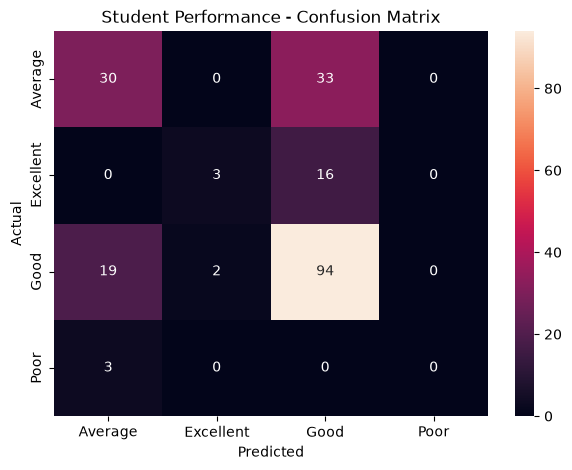

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Student Performance - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [37]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                 Feature  Importance
3         Previous_Score    0.197548
1            Study_Hours    0.193096
5         Internal_Marks    0.168903
2  Attendance_Percentage    0.141058
4       Assignment_Score    0.134190
6            Sleep_Hours    0.108099
0                    Age    0.057107


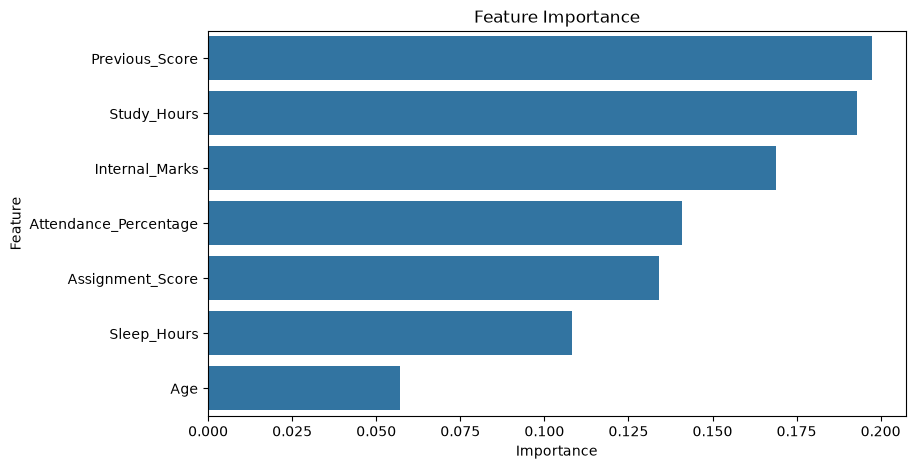

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

In [39]:
new_student = pd.DataFrame({
    "Age": [20],
    "Study_Hours": [6],
    "Attendance_Percentage": [90],
    "Previous_Score": [75],
    "Assignment_Score": [80],
    "Internal_Marks": [78],
    "Sleep_Hours": [7]
})

new_student

,Age,Study_Hours,Attendance_Percentage,Previous_Score,Assignment_Score,Internal_Marks,Sleep_Hours
0,20,6,90,75,80,78,7


In [40]:
prediction = model.predict(new_student)

print("Encoded prediction:", prediction)

Encoded prediction: [2]


In [41]:

predicted_performance = label_encoder.inverse_transform(prediction)

print(
    "Predicted Student Performance:",
    predicted_performance[0]
)

Predicted Student Performance: Good


In [42]:
print("======================================")
print(" STUDENT PERFORMANCE PREDICTION")
print("======================================")

print("Age:", new_student["Age"].iloc[0])
print("Study Hours:", new_student["Study_Hours"].iloc[0])
print("Attendance:", new_student["Attendance_Percentage"].iloc[0], "%")
print("Previous Score:", new_student["Previous_Score"].iloc[0])
print("Assignment Score:", new_student["Assignment_Score"].iloc[0])
print("Internal Marks:", new_student["Internal_Marks"].iloc[0])
print("Sleep Hours:", new_student["Sleep_Hours"].iloc[0])

print("--------------------------------------")

print(
    "Predicted Performance:",
    predicted_performance[0]
)

print("======================================")

 STUDENT PERFORMANCE PREDICTION
Age: 20
Study Hours: 6
Attendance: 90 %
Previous Score: 75
Assignment Score: 80
Internal Marks: 78
Sleep Hours: 7
--------------------------------------
Predicted Performance: Good


In [42]:
print("======================================")
print(" STUDENT PERFORMANCE PREDICTION")
print("======================================")

print("Age:", new_student["Age"].iloc[0])
print("Study Hours:", new_student["Study_Hours"].iloc[0])
print("Attendance:", new_student["Attendance_Percentage"].iloc[0], "%")
print("Previous Score:", new_student["Previous_Score"].iloc[0])
print("Assignment Score:", new_student["Assignment_Score"].iloc[0])
print("Internal Marks:", new_student["Internal_Marks"].iloc[0])
print("Sleep Hours:", new_student["Sleep_Hours"].iloc[0])

print("--------------------------------------")

print(
    "Predicted Performance:",
    predicted_performance[0]
)

print("======================================")

 STUDENT PERFORMANCE PREDICTION
Age: 20
Study Hours: 6
Attendance: 90 %
Previous Score: 75
Assignment Score: 80
Internal Marks: 78
Sleep Hours: 7
--------------------------------------
Predicted Performance: Good


In [43]:
joblib.dump(
    model,
    "student_performance_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [44]:
joblib.dump(
    label_encoder,
    "performance_label_encoder.pkl"
)

print("Label encoder saved successfully!")

Label encoder saved successfully!


In [45]:
import os

print("Files created:")
for file in os.listdir():
    if file.endswith(".pkl"):
        print("✓", file)

Files created:
✓ performance_label_encoder.pkl
✓ student_performance_model.pkl


In [46]:
loaded_model = joblib.load(
    "student_performance_model.pkl"
)

loaded_encoder = joblib.load(
    "performance_label_encoder.pkl"
)

print("================================")
print("PKL FILES LOADED SUCCESSFULLY")
print("================================")

print("Model:", type(loaded_model))
print("Encoder:", type(loaded_encoder))

print("Classes:", loaded_encoder.classes_)

PKL FILES LOADED SUCCESSFULLY
Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Encoder: <class 'sklearn.preprocessing._label.LabelEncoder'>
Classes: ['Average' 'Excellent' 'Good' 'Poor']


In [47]:
test_prediction = loaded_model.predict(new_student)

test_result = loaded_encoder.inverse_transform(
    test_prediction
)

print(
    "Prediction from saved model:",
    test_result[0]
)

Prediction from saved model: Good


In [48]:
student_2 = pd.DataFrame({
    "Age": [19],
    "Study_Hours": [2],
    "Attendance_Percentage": [55],
    "Previous_Score": [45],
    "Assignment_Score": [50],
    "Internal_Marks": [48],
    "Sleep_Hours": [6]
})

prediction_2 = loaded_model.predict(student_2)

result_2 = loaded_encoder.inverse_transform(
    prediction_2
)

print("Student 2 Performance:", result_2[0])

Student 2 Performance: Average


In [1]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [18],
    "Study_Hours": [3],
    "Attendance_Percentage": [65],
    "Previous_Score": [55],
    "Assignment_Score": [30],
    "Internal_Marks": [54],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Average


In [1]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [18],
    "Study_Hours": [3],
    "Attendance_Percentage": [65],
    "Previous_Score": [55],
    "Assignment_Score": [30],
    "Internal_Marks": [54],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Average


In [1]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [18],
    "Study_Hours": [3],
    "Attendance_Percentage": [65],
    "Previous_Score": [55],
    "Assignment_Score": [30],
    "Internal_Marks": [54],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Average


In [2]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [14],
    "Study_Hours": [2],
    "Attendance_Percentage": [25],
    "Previous_Score": [20],
    "Assignment_Score": [15],
    "Internal_Marks": [9],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Poor


In [2]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [14],
    "Study_Hours": [2],
    "Attendance_Percentage": [25],
    "Previous_Score": [20],
    "Assignment_Score": [15],
    "Internal_Marks": [9],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Poor


In [3]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [20],
    "Study_Hours": [9],
    "Attendance_Percentage": [98],
    "Previous_Score": [98],
    "Assignment_Score": [94],
    "Internal_Marks": [80],
    "Sleep_Hours": [5]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Excellent


In [3]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [20],
    "Study_Hours": [9],
    "Attendance_Percentage": [98],
    "Previous_Score": [98],
    "Assignment_Score": [94],
    "Internal_Marks": [80],
    "Sleep_Hours": [5]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Excellent


In [4]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [18],
    "Study_Hours": [3],
    "Attendance_Percentage": [80],
    "Previous_Score": [45],
    "Assignment_Score": [75],
    "Internal_Marks": [55],
    "Sleep_Hours": [9]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Average


In [2]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [18],
    "Study_Hours": [9],
    "Attendance_Percentage": [80],
    "Previous_Score": [97],
    "Assignment_Score": [90],
    "Internal_Marks": [98],
    "Sleep_Hours": [3]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Excellent


In [3]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [19],
    "Study_Hours": [2],
    "Attendance_Percentage": [15],
    "Previous_Score": [35],
    "Assignment_Score": [15],
    "Internal_Marks": [36],
    "Sleep_Hours": [10]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Poor


In [4]:
import joblib
import pandas as pd

model = joblib.load("student_performance_model.pkl")
encoder = joblib.load("performance_label_encoder.pkl")

student = pd.DataFrame({
    "Age": [19],
    "Study_Hours": [5],
    "Attendance_Percentage": [78],
    "Previous_Score": [75],
    "Assignment_Score": [85],
    "Internal_Marks": [86],
    "Sleep_Hours": [7]
})

prediction = model.predict(student)

result = encoder.inverse_transform(prediction)

print("Predicted Performance:", result[0])

Predicted Performance: Good
